# SA–LSTM vs TPE–LSTM (K=5) — RESIDUAL Forecasting

Bản chỉ chạy hai nhánh: `sa_lstm_v22_residual` và `tpe_lstm_residual`. Hai sampler tối ưu riêng số neuron hai lớp và learning rate trên cùng train/validation. Giữ năm input Copper, Aluminium, Tin, Silver, Gold, lookback=22, horizon=1 và giao thức chia/huấn luyện của notebook đã cung cấp.

Mạng học `delta_y_t = y_t - y_(t-1)` trên thang MinMax Copper fit train; khi dự báo, cộng `y_(t-1)` thật vào output delta rồi inverse_transform về giá gốc. Input vẫn là giá năm kim loại của 22 phiên t-22..t-1, không đổi sang input sai phân. Đây không phải phần dư ARIMA.

Chạy Colab/Kaggle: chọn GPU nếu có, đặt CSV_PATH hoặc để tự tìm/upload. Mặc định MODE='FULL_MODE'; QUICK_MODE dùng kiểm tra luồng. File CSV, model .keras, scalers, hình và ZIP được ghi vào thư mục `copper_sa_vs_tpe_k5_residual_only`.

Chỉ model residual được tìm kiếm, huấn luyện, đánh giá và hiển thị. Lịch search seed của nhánh residual được giữ như bản gốc để việc bỏ nhánh khác không tự đổi chuỗi khởi tạo của thí nghiệm này. Notebook đã xóa kết quả chạy cũ; chưa có kết quả mới cho tới khi bạn chạy.


## 1. Giao thức residual

- Năm input cố định: Copper, Aluminium, Tin, Silver, Gold; lookback 22, horizon 1.
- Bốn ratio 80/20, 90/10, 92.5/7.5, 95/5. Validation bằng 10% đoạn trước test. Expanding/rolling-756/recency-weighted cùng chạy ở 90/10; các ratio khác chỉ expanding, tổng 6 jobs.
- Cùng kiến trúc: LSTM(u1, sequences=True) → Dropout(.2) → LSTM(u2) → Dropout(.2) → Dense(32, ReLU) → Dense(1, linear).
- Cả SA/TPE tìm u1,u2,learning_rate trên residual validation MSE của 80/20 expanding. Khóa mọi HP trước khi huấn luyện final và predict test. Scalers fit train, không gộp train+validation.
- FULL_MODE: mỗi phương pháp/seed thử 16 cấu hình, tối đa 15 epoch/trial, final tối đa 100 epoch (patience 9), batch 64. Với một seed: 32 search fits + 12 final fits.
- QUICK_MODE: mỗi phương pháp/seed thử 4 cấu hình, tối đa 3 epoch/trial, final tối đa 5 epoch. Với một seed: 8 search fits + 12 final fits.
- Mặc định SEEDS=[42]; một seed không đo được độ dao động, std=NaN. Các test ở những ratio có thể chồng lấn, không xem như các phép thử độc lập.


In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('optuna') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','optuna>=4.2,<6'])


In [2]:
from pathlib import Path
import gc,json,time,math,hashlib,zipfile,platform
from datetime import datetime,timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from IPython.display import display,FileLink
import tensorflow as tf
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('TensorFlow:',tf.__version__,'Optuna:',optuna.__version__,'GPU:',tf.config.list_physical_devices('GPU'),flush=True)


TensorFlow: 2.21.0 Optuna: 5.0.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
MODE = 'FULL_MODE'
CSV_PATH = '/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv'
DATA_FILENAME = 'dataset_9_commodities_daily.csv'
FEATURES = ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold']
TARGET = 'Copper'
LOOKBACK, HORIZON = 22, 1
RATIOS = (0.80, 0.90, 0.925, 0.95)
PRIMARY_RATIO = 0.90
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')
SEEDS = [42]              # Muốn nghiên cứu độ ổn định: đặt [42, 710, 2024] TRƯỚC KHI CHẠY
FORECAST_MODES = ('residual',)
BASE_METHODS = ('sa_lstm_v22', 'tpe_lstm')
BATCH_SIZE = 64
MODE_CFG = {
    'QUICK_MODE': dict(epochs=5, search_epochs=3, sa_evals=4, earlystop=True),
    'FULL_MODE':  dict(epochs=100, search_epochs=15, sa_evals=16, earlystop=True),
}
assert MODE in MODE_CFG
CFG = MODE_CFG[MODE]
SPACE = {'units_1':(16,96), 'units_2':(24,160), 'learning_rate':(1e-5, 3e-3)}
INITIAL_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SEARCH_PATIENCE, FINAL_PATIENCE = 4, 9
assert min(RATIOS)==.80 and HORIZON==1 and len(set(SEEDS))==len(SEEDS)
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else (Path('/content') if Path('/content').is_dir() else Path.cwd())
OUT = ROOT/'copper_sa_vs_tpe_k5_residual_only'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True,exist_ok=False)
JOBS = [(ratio,scheme) for ratio in RATIOS for scheme in (SCHEMES if ratio==PRIMARY_RATIO else ('expanding',))]
METHOD_LABELS = [f'{method}_{mode}' for mode in FORECAST_MODES for method in BASE_METHODS]
print('Output:',OUT)
print(f'{MODE}: {len(BASE_METHODS)*len(FORECAST_MODES)*CFG["sa_evals"]*len(SEEDS)} search fits'
      f' + {len(BASE_METHODS)*len(FORECAST_MODES)*len(JOBS)*len(SEEDS)} final fits',flush=True)


Output: /kaggle/working/copper_sa_vs_tpe_k5_residual_only/20261120T125750886401Z
FULL_MODE: 32 search fits + 12 final fits


## 2. Đọc và xử lý dữ liệu K=5

Chỉ sử dụng giá của 5 kim loại cố định. Scaler X và y fit trên train (không chứa validation/test). Target Copper(t) không nằm trong input cửa sổ t−22…t−1.


In [4]:
def resolve_csv(csv_path, filename, input_root=Path('/kaggle/input')):
    """Ưu tiên đường dẫn chỉ định, sau đó tìm Kaggle/Colab/local; Colab cho upload."""
    if csv_path is not None:
        p=Path(csv_path).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f'CSV_PATH không tồn tại: {p}. Đặt CSV_PATH=None nếu muốn tự tìm.')
        return p
    roots=[input_root,Path('/content'),Path.cwd(),Path('/mnt/data')]
    names=(filename,'commodities_9_daily.csv')
    found=[]
    for root in roots:
        if not root.is_dir():continue
        for name in names:
            found.extend(p.resolve() for p in root.rglob(name) if p.is_file())
    found=sorted(set(found))
    if len(found)==1:return found[0]
    if len(found)>1:
        raise FileNotFoundError(f'Tìm thấy nhiều CSV: {found}. Hãy đặt CSV_PATH cụ thể.')
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Không tìm thấy {names}. Upload file hoặc đặt CSV_PATH.')
    uploaded=files.upload()
    if len(uploaded)!=1:
        raise FileNotFoundError('Hãy upload đúng một file CSV và chạy lại cell này.')
    p=Path('/content')/next(iter(uploaded))
    if not p.is_file():p=Path(next(iter(uploaded)))
    if not p.is_file():raise FileNotFoundError(f'Không tìm thấy file mới upload: {p}')
    return p

def clean_data(raw):
    raw=raw.copy()
    raw.columns=[str(c).strip().lstrip('\ufeff') for c in raw.columns]
    aliases={'Price_Copper':'Copper','Price_WTI':'WTI','Price_Gold':'Gold','Price_Silver':'Silver'}
    if raw.columns.duplicated().any() or any(a in raw.columns and b in raw.columns for a,b in aliases.items()):
        raise ValueError('Tên biến trùng/nhập nhằng.')
    raw=raw.rename(columns=aliases)
    required=['Date']+FEATURES
    missing=set(required)-set(raw.columns)
    if missing:raise ValueError(f'Thiếu cột: {missing}')
    raw=raw[required].copy()
    raw.Date=pd.to_datetime(raw.Date,errors='coerce',utc=True).dt.tz_convert(None).dt.normalize()
    if raw.Date.isna().any() or raw.Date.duplicated().any():raise ValueError('Ngày không hợp lệ hoặc trùng.')
    for key in FEATURES:raw[key]=pd.to_numeric(raw[key],errors='coerce')
    n=len(raw)
    data=raw.replace([np.inf,-np.inf],np.nan).dropna().sort_values('Date').reset_index(drop=True)
    if len(data)<=1000:raise ValueError('Cần hơn 1000 dòng hợp lệ theo giao thức V22.')
    if not (data[FEATURES]>0).all().all():raise ValueError('Giá <=0: kiểm tra nguồn CSV trước khi chạy.')
    return data,dict(rows_source=n,rows_used=len(data),rows_removed=n-len(data),start=str(data.Date.min()),end=str(data.Date.max()))

DATA_PATH=resolve_csv(CSV_PATH,DATA_FILENAME)
data,quality=clean_data(pd.read_csv(DATA_PATH,encoding='utf-8-sig'))
data.to_csv(OUT/'dataset_snapshot.csv',index=False,encoding='utf-8-sig')
DATA_SHA=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
(OUT/'data_quality.json').write_text(json.dumps(quality,indent=2),encoding='utf-8')
print(DATA_PATH,quality,flush=True)
display(data.head())


/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv {'rows_source': 2710, 'rows_used': 2710, 'rows_removed': 0, 'start': '2016-01-13 00:00:00', 'end': '2026-11-13 00:00:00'}


,Date,Copper,Aluminium,Tin,Silver,Gold
0,2016-01-13,1.9560,1462.5,13305.0,14.156,1087.1
1,2016-01-14,1.9760,1483.0,13260.0,13.748,1073.6
2,2016-01-15,1.9435,1473.0,13205.0,13.896,1090.7
3,2016-01-19,1.9775,1481.0,13225.0,14.121,1090.7
4,2016-01-20,1.9595,1469.0,13390.0,14.160,1106.2


In [5]:
def make_context(frame, ratio, scheme='expanding', feature_set='five_inputs', val_fraction=0.10, include_test=False):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = list(FEATURES)
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    visible = frame if include_test else frame.iloc[:split]
    x = xsc.transform(visible[cols]).astype('float32')
    y = ysc.transform(visible[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n) if include_test else None
    assert tr['idx'][-1] < va['idx'][0]
    if include_test: assert va['idx'][-1] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, **({'test':te} if include_test else {}), 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}


In [6]:
audit=[]
for ratio,scheme in JOBS:
    ctx=make_context(data,ratio,scheme)
    for part in ['train','val']:
        b=ctx[part]
        audit.append(dict(ratio=ratio,scheme=scheme,part=part,samples=len(b['idx']),
                          first_target=str(b['date'][0]),last_target=str(b['date'][-1])))
    test_start=ctx['test_start']
    audit.append(dict(ratio=ratio,scheme=scheme,part='test',samples=len(data)-test_start,
                      first_target=str(data.Date.iloc[test_start]),last_target=str(data.Date.iloc[-1])))
    assert 'test' not in ctx
split_df=pd.DataFrame(audit)
split_df.to_csv(OUT/'data_split_summary.csv',index=False)
display(split_df)
search_ctx=make_context(data,min(RATIOS),'expanding')
assert 'test' not in search_ctx


,ratio,scheme,part,samples,first_target,last_target
0,0.800,expanding,train,1929,2016-02-16T00:00:00.000000000,2023-12-06T00:00:00.000000000
1,0.800,expanding,val,217,2023-12-07T00:00:00.000000000,2024-10-04T00:00:00.000000000
2,0.800,expanding,test,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,0.900,expanding,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000
4,0.900,expanding,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
5,0.900,expanding,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
6,0.900,rolling_756,train,734,2021-09-24T00:00:00.000000000,2024-11-12T00:00:00.000000000
7,0.900,rolling_756,val,244,2024-11-13T00:00:00.000000000,2025-10-28T00:00:00.000000000
8,0.900,rolling_756,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
9,0.900,recency_weighted,train,2173,2016-02-16T00:00:00.000000000,2024-11-12T00:00:00.000000000


In [7]:
# Chỉ hỗ trợ mục tiêu residual; không có nhánh dự báo mức giá thuần.
def training_target(block, forecast_mode):
    if forecast_mode != 'residual':
        raise ValueError(f'Chỉ hỗ trợ residual: {forecast_mode}')
    return (block['y'] - block['prev']).astype('float32')


def restore_price_scaled(predicted_network_output, previous_copper_scaled, forecast_mode):
    if forecast_mode != 'residual':
        raise ValueError(f'Chỉ hỗ trợ residual: {forecast_mode}')
    pred=np.asarray(predicted_network_output,dtype='float64').reshape(-1)
    prev=np.asarray(previous_copper_scaled,dtype='float64').reshape(-1)
    if pred.shape != prev.shape:raise ValueError('Sai shape giữa prediction và prev Copper')
    return prev+pred

for blockname in ('train','val'):
    b=search_ctx[blockname]
    assert np.allclose(training_target(b,'residual')+b['prev'],b['y'],atol=1e-6)
    assert np.allclose(restore_price_scaled(training_target(b,'residual'),b['prev'],'residual'),b['y'],atol=1e-6)
assert search_ctx['train']['idx'].max()<search_ctx['val']['idx'].min()
assert search_ctx['xsc'].n_samples_seen_==search_ctx['val_start']-search_ctx['fit_start']
print('PASS: target residual, hoàn nguyên giá, shape và scaler train-only.')


PASS: target residual, hoàn nguyên giá, shape và scaler train-only.


## 3. LSTM học mức thay đổi giá

Mạng học `y_t-y_(t-1)` đã chuẩn hóa và trả về `pred_delta_t`. Dự báo mức giá được tính `pred_y_t=y_(t-1)+pred_delta_t`, sau đó inverse-transform về đơn vị nguồn CSV. Input X vẫn gồm (22 phiên, 5 kim loại); residual không đổi các biến đầu vào thành sai phân.


In [8]:
def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (chỉ H=1, HP tìm mới riêng cho từng feature set)."""
    h = hp or INITIAL_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))

    model = tf.keras.Sequential(name='Shared_V22_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')


In [9]:
def train_config(ctx, hp, seed, epochs, patience, forecast_mode, model_path=None):
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(int(seed))
    model = build_sa_lstm(ctx['train']['X'].shape[1:],hp)
    y_train_mode = training_target(ctx['train'],forecast_mode)
    y_val_mode = training_target(ctx['val'],forecast_mode)
    start=time.perf_counter()
    try:
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=patience,restore_best_weights=True),
                   tf.keras.callbacks.TerminateOnNaN()]
        history=model.fit(ctx['train']['X'],y_train_mode,
                          validation_data=(ctx['val']['X'],y_val_mode),
                          epochs=epochs,batch_size=BATCH_SIZE,shuffle=False,
                          sample_weight=sample_weights(len(ctx['train']['idx']),ctx['scheme']),
                          callbacks=callbacks,verbose=2 if MODE=='QUICK_MODE' else 0)
        if not all(np.isfinite(np.asarray(history.history[key])).all() for key in ['loss','val_loss']):
            raise FloatingPointError('Loss không hữu hạn; kiểm tra dữ liệu/hyperparameters')
        pred_val=model.predict(ctx['val']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
        if not np.isfinite(pred_val).all():raise FloatingPointError('Validation prediction không hữu hạn')
        score=float(mean_squared_error(y_val_mode,pred_val))
        fit=dict(val_mse=score,fit_seconds=time.perf_counter()-start,
                 epochs_run=len(history.history['loss']),history=history.history)
        if model_path is not None:model.save(model_path)
        return fit
    finally:
        del model;tf.keras.backend.clear_session();gc.collect()


## 4. Tìm siêu tham số cho hai mô hình residual

Trong mỗi seed, SA và TPE dùng chung miền tham số, ngân sách, kiến trúc, dữ liệu và lịch trial seed. Chọn HP bằng residual validation MSE, không đọc test khi tuning. Sau khi khóa HP trên 80/20 expanding, huấn luyện final cho 6 jobs. Search seed giữ 12026 + seed_index*1000 theo nhánh residual của notebook đầu vào.


In [10]:
def clip_hp(h):
    return {'units_1':int(np.clip(round(h['units_1']), *SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']), *SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'], *SPACE['learning_rate']))}

def neighbor(h, rng, temp):
    # SA neighborhood defined in architecture space and log-LR space.
    h = dict(h); dim = rng.choice(['units_1','units_2','learning_rate'])
    if dim == 'learning_rate':
        h[dim] = float(h[dim] * np.exp(rng.normal(0, 0.65)))
    else:
        h[dim] = int(h[dim] + rng.choice([-1,1])*rng.choice([8,16,24]))
    return clip_hp(h)


In [11]:
def search_method(method, forecast_mode, ctx, folder, budget, search_seed):
    assert method in BASE_METHODS and forecast_mode in FORECAST_MODES
    model_key=f'{method}_{forecast_mode}'
    rows=[];start=time.perf_counter()
    def evaluate(hp,k):
        fit=train_config(ctx,hp,search_seed+k,CFG['search_epochs'],SEARCH_PATIENCE,
                         forecast_mode=forecast_mode)
        score=float(fit['val_mse'])
        if not np.isfinite(score):raise FloatingPointError('Validation MSE không hữu hạn')
        return score,fit
    def record(hp,score,fit,**extra):
        rows.append(dict(method=method,forecast_mode=forecast_mode,model_key=model_key,
                         trial=len(rows)+1,val_mse_scaled=score,
                         best_val_mse_scaled=min([r['best_val_mse_scaled'] for r in rows]+[score]),
                         fit_seconds=fit['fit_seconds'],epochs_run=fit['epochs_run'],
                         trial_train_seed=search_seed+len(rows),elapsed_seconds=time.perf_counter()-start,
                         **hp,**extra))
        pd.DataFrame(rows).to_csv(folder/f'{model_key}_search_trials.csv',index=False)
        print(f'{model_key} [{len(rows)}/{budget}] val={score:.7g}, '
              f'best={rows[-1]["best_val_mse_scaled"]:.7g}',flush=True)
    if method=='sa_lstm_v22':
        rng=np.random.default_rng(search_seed)
        current=clip_hp(INITIAL_HP);current_loss=float('inf')
        for k in range(budget):
            temperature=float(max(.05,.88**k))
            hp=dict(current) if k==0 else neighbor(current,rng,temperature)
            score,fit=evaluate(hp,k)
            effective_temp=max(1e-8,temperature*max(score,current_loss if np.isfinite(current_loss) else score,1e-5))
            accepted=(score<=current_loss) or (rng.random()<np.exp(-max(0.,score-current_loss)/effective_temp))
            if accepted:current,current_loss=dict(hp),score
            record(hp,score,fit,temperature=temperature,accepted=bool(accepted))
    elif method=='tpe_lstm':
        study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(
            seed=search_seed,n_startup_trials=min(10,max(2,budget//3)),multivariate=False),
            pruner=optuna.pruners.NopPruner())
        study.enqueue_trial(dict(INITIAL_HP))
        def objective(trial):
            hp=dict(units_1=trial.suggest_int('units_1',*SPACE['units_1']),
                    units_2=trial.suggest_int('units_2',*SPACE['units_2']),
                    learning_rate=trial.suggest_float('learning_rate',*SPACE['learning_rate'],log=True))
            score,fit=evaluate(hp,trial.number)
            record(hp,score,fit)
            return score
        study.optimize(objective,n_trials=budget,n_jobs=1)
    else:raise ValueError(method)
    assert len(rows)==budget
    best=min(rows,key=lambda r:r['val_mse_scaled'])
    return dict(method=method,forecast_mode=forecast_mode,model_key=model_key,
                best_hp={key:best[key] for key in INITIAL_HP},
                best_val_mse_scaled=best['val_mse_scaled'],evaluations=len(rows),
                total_search_epochs=sum(r['epochs_run'] for r in rows),
                search_fit_seconds=sum(r['fit_seconds'] for r in rows),
                search_wall_seconds=time.perf_counter()-start),rows


In [12]:
manifest=dict(mode=MODE, config=CFG, features=FEATURES, target=TARGET,
              lookback=LOOKBACK,horizon=HORIZON, ratios=RATIOS,schemes=SCHEMES,
              jobs=JOBS,seeds=SEEDS,forecast_modes=FORECAST_MODES,base_methods=BASE_METHODS,
              space=SPACE, initial_hp=INITIAL_HP,search_reference_ratio=min(RATIOS),
              search_reference_scheme='expanding',dataset=str(DATA_PATH),dataset_sha256=DATA_SHA,
              python=platform.python_version(),versions={p:metadata.version(p) for p in
              ['tensorflow','optuna','numpy','pandas','scikit-learn']})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
search_results=[];search_logs=[]
for seed_index,seed in enumerate(SEEDS):
    for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
        folder=OUT/f'seed_{seed}'/forecast_mode;folder.mkdir(parents=True,exist_ok=True)
        # SA/TPE của CÙNG mode dùng chung search seed/trial seeds.
        search_seed=12026+seed_index*1000
        order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
        for method in order:
            print(f'BEGIN search {method}_{forecast_mode}, seed={seed}',flush=True)
            best,logs=search_method(method,forecast_mode,search_ctx,folder,CFG['sa_evals'],search_seed)
            best['seed']=seed;best['folder']=str(folder);search_results.append(best)
            for row in logs:row['seed']=seed
            search_logs.extend(logs)
# Khóa HP cho hai phương pháp residual ở mọi seed TRƯỚC khi dự báo test.
(OUT/'locked_best_hyperparameters.json').write_text(json.dumps(search_results,indent=2),encoding='utf-8')
search_df=pd.DataFrame([{k:v for k,v in r.items() if k not in ['best_hp','folder']} for r in search_results])
search_df.to_csv(OUT/'search_comparison.csv',index=False)
search_trials=pd.DataFrame(search_logs);search_trials.to_csv(OUT/'all_search_trials.csv',index=False)
display(search_df)


BEGIN search sa_lstm_v22_residual, seed=42
sa_lstm_v22_residual [1/16] val=0.0003843618, best=0.0003843618
sa_lstm_v22_residual [2/16] val=0.0003866986, best=0.0003843618
sa_lstm_v22_residual [3/16] val=0.000388529, best=0.0003843618
sa_lstm_v22_residual [4/16] val=0.0003818952, best=0.0003818952
sa_lstm_v22_residual [5/16] val=0.000381284, best=0.000381284
sa_lstm_v22_residual [6/16] val=0.0003993052, best=0.000381284
sa_lstm_v22_residual [7/16] val=0.0003833555, best=0.000381284
sa_lstm_v22_residual [8/16] val=0.0003887212, best=0.000381284
sa_lstm_v22_residual [9/16] val=0.0004140786, best=0.000381284
sa_lstm_v22_residual [10/16] val=0.0004097869, best=0.000381284
sa_lstm_v22_residual [11/16] val=0.0003891997, best=0.000381284
sa_lstm_v22_residual [12/16] val=0.0003971731, best=0.000381284
sa_lstm_v22_residual [13/16] val=0.0004191372, best=0.000381284
sa_lstm_v22_residual [14/16] val=0.0005499438, best=0.000381284
sa_lstm_v22_residual [15/16] val=0.0004344079, best=0.000381284
sa_l

,method,forecast_mode,model_key,best_val_mse_scaled,evaluations,total_search_epochs,search_fit_seconds,search_wall_seconds,seed
0,sa_lstm_v22,residual,sa_lstm_v22_residual,0.000381,16,153,96.440042,119.367096,42
1,tpe_lstm,residual,tpe_lstm_residual,0.000377,16,166,97.655141,128.628505,42


## 5. Huấn luyện final sau khi đã khóa HP

Mỗi cấu hình (ratio, strategy, seed, method, mode) được huấn luyện **từ đầu**, dùng train để cập nhật trọng số, validation để EarlyStopping. Không gộp train+validation; không dùng test để tìm HP/epoch. Lưu model `.keras` riêng cho từng mode; lưu scaler theo từng split/strategy.


In [13]:
final_models=[];final_training=[]
for ratio,scheme in JOBS:
    ctx=make_context(data,ratio,scheme,include_test=False)
    assert 'test' not in ctx
    for seed_index,seed in enumerate(SEEDS):
        for mode_idx,forecast_mode in enumerate(FORECAST_MODES):
            order=list(BASE_METHODS if seed_index%2==0 else BASE_METHODS[::-1])
            for method in order:
                model_key=f'{method}_{forecast_mode}'
                best=next(r for r in search_results if r['method']==method and
                          r['seed']==seed and r['forecast_mode']==forecast_mode)
                folder=OUT/f'ratio_{ratio:.3f}'/scheme/f'seed_{seed}'
                folder.mkdir(parents=True,exist_ok=True)
                model_path=folder/f'{model_key}.keras'
                print(f'BEGIN final {model_key} ratio={ratio}, scheme={scheme}, seed={seed}',flush=True)
                fit=train_config(ctx,best['best_hp'],seed,CFG['epochs'],FINAL_PATIENCE,
                                 forecast_mode=forecast_mode,model_path=model_path)
                pd.DataFrame(fit['history']).to_csv(folder/f'{model_key}_loss.csv',index=False)
                recipe=dict(method=method,forecast_mode=forecast_mode,model_key=model_key,
                            ratio=ratio,scheme=scheme,seed=seed,model_path=str(model_path),
                            hp=best['best_hp'],final_val_mse_scaled=fit['val_mse'],
                            final_fit_seconds=fit['fit_seconds'],final_epochs_run=fit['epochs_run'])
                final_models.append(recipe)
                final_training.append({k:v for k,v in recipe.items() if k not in ['model_path','hp']})
                pd.DataFrame(final_training).to_csv(OUT/'final_training.csv',index=False)
    np.savez(OUT/f'ratio_{ratio:.3f}'/scheme/'scalers.npz',
             x_scale=ctx['xsc'].scale_,x_offset=ctx['xsc'].min_,
             y_scale=ctx['ysc'].scale_,y_offset=ctx['ysc'].min_,features=np.array(FEATURES))
(OUT/'final_model_recipes.json').write_text(json.dumps(final_models,indent=2),encoding='utf-8')
print('Đã hoàn tất',len(final_models),'final model fits, khóa và lưu toàn bộ model.')


BEGIN final sa_lstm_v22_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final tpe_lstm_residual ratio=0.8, scheme=expanding, seed=42
BEGIN final sa_lstm_v22_residual ratio=0.9, scheme=expanding, seed=42
BEGIN final tpe_lstm_residual ratio=0.9, scheme=expanding, seed=42
BEGIN final sa_lstm_v22_residual ratio=0.9, scheme=rolling_756, seed=42
BEGIN final tpe_lstm_residual ratio=0.9, scheme=rolling_756, seed=42
BEGIN final sa_lstm_v22_residual ratio=0.9, scheme=recency_weighted, seed=42
BEGIN final tpe_lstm_residual ratio=0.9, scheme=recency_weighted, seed=42
BEGIN final sa_lstm_v22_residual ratio=0.925, scheme=expanding, seed=42
BEGIN final tpe_lstm_residual ratio=0.925, scheme=expanding, seed=42
BEGIN final sa_lstm_v22_residual ratio=0.95, scheme=expanding, seed=42
BEGIN final tpe_lstm_residual ratio=0.95, scheme=expanding, seed=42
Đã hoàn tất 12 final model fits, khóa và lưu toàn bộ model.


## 6. Đánh giá trên giá gốc

`pred_scaled=previous_copper_scaled+network_output`, rồi inverse-transform bằng y scaler train. Naive là Copper(t-1) thực tế. Chỉ sau khi mọi HP và final model được khóa mới tạo test context. Hai phương pháp phải khớp ngày và giá thật/Naive trong từng job.

Báo cáo MAE/RMSE/MSE/MASE/R²/Directional Accuracy, cải thiện MAE so Naive và các thống kê delta. Một đường dự báo sát giá chưa đủ cho thấy mô hình học biến động; phải xem có vượt Naive và delta dự báo có hữu ích không.


In [14]:
def score_test(ctx,pred_scaled,forecast_mode,network_output):
    y=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['y'],dtype='float64')[:,None]).ravel()
    p=ctx['ysc'].inverse_transform(np.asarray(pred_scaled).reshape(-1,1)).ravel()
    base=ctx['ysc'].inverse_transform(np.asarray(ctx['test']['prev'],dtype='float64')[:,None]).ravel()
    if len(y)!=len(p) or not np.isfinite(p).all():raise FloatingPointError('Test prediction không hợp lệ.')
    mse=float(mean_squared_error(y,p));mae=float(mean_absolute_error(y,p))
    naive_mae=float(mean_absolute_error(y,base))
    train_values=data[TARGET].iloc[ctx['fit_start']:ctx['val_start']].to_numpy()
    denom=float(np.mean(np.abs(np.diff(train_values))))
    actual_delta=y-base;pred_delta=p-base
    corr=float(np.corrcoef(actual_delta,pred_delta)[0,1]) if (
        np.std(actual_delta)>1e-12 and np.std(pred_delta)>1e-12) else np.nan
    metrics=dict(mae=mae,mse=mse,rmse=float(np.sqrt(mse)),r2=float(r2_score(y,p)),
                 mse_scaled=float(mean_squared_error(ctx['test']['y'],pred_scaled)),
                 mase=mae/denom if denom>0 else np.nan,
                 mae_naive=naive_mae,
                 mae_improvement_pct=100*(naive_mae-mae)/naive_mae if naive_mae>0 else np.nan,
                 directional_accuracy_pct=float(100*np.mean(np.sign(pred_delta)==np.sign(actual_delta))),
                 actual_delta_std=float(np.std(actual_delta)),
                 predicted_delta_std=float(np.std(pred_delta)),
                 predicted_delta_mean_abs=float(np.mean(np.abs(pred_delta))),
                 delta_corr=corr)
    return metrics,pd.DataFrame(dict(Date=ctx['test']['date'],actual=y,pred=p,naive=base,
                                     actual_delta=actual_delta,pred_delta=pred_delta,
                                     network_output=np.asarray(network_output).reshape(-1)))

results=[];prediction_parts=[]
for recipe in final_models:
    ratio,scheme,seed,method,forecast_mode=[recipe[k] for k in
                                           ['ratio','scheme','seed','method','forecast_mode']]
    ctx=make_context(data,ratio,scheme,include_test=True)
    model=tf.keras.models.load_model(recipe['model_path'])
    net=model.predict(ctx['test']['X'],batch_size=BATCH_SIZE,verbose=0).ravel()
    pred_scaled=restore_price_scaled(net,ctx['test']['prev'],forecast_mode)
    if forecast_mode=='residual':
        assert np.allclose(pred_scaled-ctx['test']['prev'],net,atol=1e-6)
    m,part=score_test(ctx,pred_scaled,forecast_mode,net)
    row={k:v for k,v in recipe.items() if k not in ['model_path','hp']}
    row.update(m,n_test=len(part),test_start=str(part.Date.min()),test_end=str(part.Date.max()))
    results.append(row)
    for key,value in dict(ratio=ratio,scheme=scheme,seed=seed,method=method,
                          forecast_mode=forecast_mode,model_key=recipe['model_key']).items():
        part[key]=value
    prediction_parts.append(part)
    pd.DataFrame(results).to_csv(OUT/'metrics_by_run.csv',index=False)
    print(f'TEST {recipe["model_key"]} ratio={ratio} {scheme} seed={seed}: MAE={m["mae"]:.6g}, '
          f'RMSE={m["rmse"]:.6g}, Δcorr={m["delta_corr"]:.4g}',flush=True)
    del model;tf.keras.backend.clear_session();gc.collect()
results_df=pd.DataFrame(results)
predictions_df=pd.concat(prediction_parts,ignore_index=True)
predictions_df.to_csv(OUT/'test_predictions.csv',index=False)

for key,g in predictions_df.groupby(['ratio','scheme','seed']):
    assert set(g.model_key)==set(METHOD_LABELS),key
    ref=g[g.model_key==METHOD_LABELS[0]].sort_values('Date')
    for model_key in METHOD_LABELS[1:]:
        other=g[g.model_key==model_key].sort_values('Date')
        assert np.array_equal(ref.Date.to_numpy(),other.Date.to_numpy()),(key,model_key)
        assert np.allclose(ref.actual,other.actual) and np.allclose(ref.naive,other.naive),(key,model_key)
assert len(results_df)==len(JOBS)*len(SEEDS)*len(METHOD_LABELS)
print('PASS: cả 2 mô hình residual dùng cùng ngày test và cùng Copper thật/Naive trong từng job.')
display(results_df)


TEST sa_lstm_v22_residual ratio=0.8 expanding seed=42: MAE=0.0710299, RMSE=0.109306, Δcorr=0.0003257
TEST tpe_lstm_residual ratio=0.8 expanding seed=42: MAE=0.12109, RMSE=0.168915, Δcorr=-0.02265
TEST sa_lstm_v22_residual ratio=0.9 expanding seed=42: MAE=0.0809678, RMSE=0.106303, Δcorr=-0.03679
TEST tpe_lstm_residual ratio=0.9 expanding seed=42: MAE=0.100064, RMSE=0.128955, Δcorr=-0.003208
TEST sa_lstm_v22_residual ratio=0.9 rolling_756 seed=42: MAE=0.0772551, RMSE=0.101446, Δcorr=0.01735
TEST tpe_lstm_residual ratio=0.9 rolling_756 seed=42: MAE=0.101542, RMSE=0.129644, Δcorr=-0.01336
TEST sa_lstm_v22_residual ratio=0.9 recency_weighted seed=42: MAE=0.0814714, RMSE=0.107021, Δcorr=0.01207
TEST tpe_lstm_residual ratio=0.9 recency_weighted seed=42: MAE=0.108559, RMSE=0.139261, Δcorr=-0.009727
TEST sa_lstm_v22_residual ratio=0.925 expanding seed=42: MAE=0.0768876, RMSE=0.101366, Δcorr=-0.01082
TEST tpe_lstm_residual ratio=0.925 expanding seed=42: MAE=0.0748464, RMSE=0.0982211, Δcorr=0.088

,method,forecast_mode,model_key,ratio,scheme,seed,final_val_mse_scaled,final_fit_seconds,final_epochs_run,mae,...,mae_naive,mae_improvement_pct,directional_accuracy_pct,actual_delta_std,predicted_delta_std,predicted_delta_mean_abs,delta_corr,n_test,test_start,test_end
0,sa_lstm_v22,residual,sa_lstm_v22_residual,0.800,expanding,42,0.000381,11.825427,27,0.071030,...,0.069001,-2.939656,46.309963,0.107963,0.009944,0.011828,0.000326,542,2024-10-07 00:00:00,2026-11-13 00:00:00
1,tpe_lstm,residual,tpe_lstm_residual,0.800,expanding,42,0.000382,9.095469,19,0.121090,...,0.069001,-75.488428,47.047970,0.107963,0.092489,0.086089,-0.022650,542,2024-10-07 00:00:00,2026-11-13 00:00:00
2,sa_lstm_v22,residual,sa_lstm_v22_residual,0.900,expanding,42,0.001388,7.007736,12,0.080968,...,0.077077,-5.048310,53.136531,0.100971,0.014280,0.031755,-0.036786,271,2025-10-29 00:00:00,2026-11-13 00:00:00
3,tpe_lstm,residual,tpe_lstm_residual,0.900,expanding,42,0.001424,11.027428,23,0.100064,...,0.077077,-29.824180,45.387454,0.100971,0.048878,0.059977,-0.003208,271,2025-10-29 00:00:00,2026-11-13 00:00:00
4,sa_lstm_v22,residual,sa_lstm_v22_residual,0.900,rolling_756,42,0.003826,8.357175,25,0.077255,...,0.077077,-0.231358,48.708487,0.100971,0.009512,0.008514,0.017351,271,2025-10-29 00:00:00,2026-11-13 00:00:00
5,tpe_lstm,residual,tpe_lstm_residual,0.900,rolling_756,42,0.003949,17.565965,66,0.101542,...,0.077077,-31.741432,46.494465,0.100971,0.043004,0.064624,-0.013363,271,2025-10-29 00:00:00,2026-11-13 00:00:00
6,sa_lstm_v22,residual,sa_lstm_v22_residual,0.900,recency_weighted,42,0.001393,8.531478,16,0.081471,...,0.077077,-5.701655,52.767528,0.100971,0.016078,0.035782,0.012074,271,2025-10-29 00:00:00,2026-11-13 00:00:00
7,tpe_lstm,residual,tpe_lstm_residual,0.900,recency_weighted,42,0.001419,10.677337,22,0.108559,...,0.077077,-40.845588,45.756458,0.100971,0.058981,0.071385,-0.009727,271,2025-10-29 00:00:00,2026-11-13 00:00:00
8,sa_lstm_v22,residual,sa_lstm_v22_residual,0.925,expanding,42,0.001611,8.459148,16,0.076888,...,0.075116,-2.358229,52.450980,0.098398,0.008052,0.022125,-0.010823,204,2026-01-30 00:00:00,2026-11-13 00:00:00
9,tpe_lstm,residual,tpe_lstm_residual,0.925,expanding,42,0.001615,38.233591,93,0.074846,...,0.075116,0.359151,58.333333,0.098398,0.003373,0.003964,0.088599,204,2026-01-30 00:00:00,2026-11-13 00:00:00


In [15]:
metrics=['mae','rmse','mse','mase','mae_improvement_pct','directional_accuracy_pct',
         'delta_corr','actual_delta_std','predicted_delta_std','predicted_delta_mean_abs']
summary=results_df.groupby(['ratio','scheme','forecast_mode','method'])[metrics+['final_fit_seconds']].agg(['mean','std'])
summary.to_csv(OUT/'summary_mean_std.csv')
display(summary)

# So SA vs TPE CHỈ trong cùng target mode, ratio, scheme, seed.
paired_sampler=results_df.pivot(index=['ratio','scheme','seed','forecast_mode'],columns='method',values=metrics)
difference=pd.DataFrame({f'TPE_minus_SA_{m}':paired_sampler[m]['tpe_lstm']-paired_sampler[m]['sa_lstm_v22']
                         for m in metrics})
for m in ['mae','rmse','mse']:
    denom=paired_sampler[m]['sa_lstm_v22'].replace(0,np.nan)
    difference[f'TPE_{m}_reduction_pct']=100*(paired_sampler[m]['sa_lstm_v22']-paired_sampler[m]['tpe_lstm'])/denom
difference.to_csv(OUT/'paired_comparison_SA_vs_TPE_by_mode.csv');display(difference)

naive_results=results_df[['ratio','scheme','seed','mae_naive','n_test']].drop_duplicates()
naive_results.to_csv(OUT/'naive_baseline.csv',index=False)
print('TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.')
print('mae_improvement_pct > 0 nghĩa là mô hình giảm MAE so với Naive.')
if len(SEEDS)==1:print('Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.')


mae          rmse      \
                                                      mean std      mean std   
ratio scheme           forecast_mode method                                    
0.800 expanding        residual      sa_lstm_v22  0.071030 NaN  0.109306 NaN   
                                     tpe_lstm     0.121090 NaN  0.168915 NaN   
0.900 expanding        residual      sa_lstm_v22  0.080968 NaN  0.106303 NaN   
                                     tpe_lstm     0.100064 NaN  0.128955 NaN   
      recency_weighted residual      sa_lstm_v22  0.081471 NaN  0.107021 NaN   
                                     tpe_lstm     0.108559 NaN  0.139261 NaN   
      rolling_756      residual      sa_lstm_v22  0.077255 NaN  0.101446 NaN   
                                     tpe_lstm     0.101542 NaN  0.129644 NaN   
0.925 expanding        residual      sa_lstm_v22  0.076888 NaN  0.101366 NaN   
                                     tpe_lstm     0.074846 NaN  0.098221 NaN   
0.950 expanding        residual      sa_lstm_v22  0.072863 NaN  0.097304 NaN   
                                     tpe_lstm     0.072753 NaN  0.096611 NaN   

                                                       mse          mase      \
                                                      mean std      mean std   
ratio scheme           forecast_mode method                                    
0.800 expanding        residual      sa_lstm_v22  0.011948 NaN  2.158956 NaN   
                                     tpe_lstm     0.028532 NaN  3.680523 NaN   
0.900 expanding        residual      sa_lstm_v22  0.011300 NaN  2.359938 NaN   
                                     tpe_lstm     0.016629 NaN  2.916535 NaN   
      recency_weighted residual      sa_lstm_v22  0.011454 NaN  2.374616 NaN   
                                     tpe_lstm     0.019394 NaN  3.164134 NaN   
      rolling_756      residual      sa_lstm_v22  0.010291 NaN  1.633771 NaN   
                                     tpe_lstm     0.016808 NaN  2.147385 NaN   
0.925 expanding        residual      sa_lstm_v22  0.010275 NaN  2.238829 NaN   
                                     tpe_lstm     0.009647 NaN  2.179393 NaN   
0.950 expanding        residual      sa_lstm_v22  0.009468 NaN  2.055690 NaN   
                                     tpe_lstm     0.009334 NaN  2.052591 NaN   

                                                 mae_improvement_pct      ...  \
                                                                mean std  ...   
ratio scheme           forecast_mode method                               ...   
0.800 expanding        residual      sa_lstm_v22           -2.939656 NaN  ...   
                                     tpe_lstm             -75.488428 NaN  ...   
0.900 expanding        residual      sa_lstm_v22           -5.048310 NaN  ...   
                                     tpe_lstm             -29.824180 NaN  ...   
      recency_weighted residual      sa_lstm_v22           -5.701655 NaN  ...   
                                     tpe_lstm             -40.845588 NaN  ...   
      rolling_756      residual      sa_lstm_v22           -0.231358 NaN  ...   
                                     tpe_lstm             -31.741432 NaN  ...   
0.925 expanding        residual      sa_lstm_v22           -2.358229 NaN  ...   
                                     tpe_lstm               0.359151 NaN  ...   
0.950 expanding        residual      sa_lstm_v22           -0.086919 NaN  ...   
                                     tpe_lstm               0.063936 NaN  ...   

                                                 delta_corr      \
                                                       mean std   
ratio scheme           forecast_mode method                       
0.800 expanding        residual      sa_lstm_v22   0.000326 NaN   
                                     tpe_lstm     -0.022650 NaN   
0.900 expanding        residual      sa_lstm_v22  -0.036786 NaN   
                                   

TPE_minus_SA_mae  \
ratio scheme           seed forecast_mode                     
0.800 expanding        42   residual               0.050060   
0.900 expanding        42   residual               0.019096   
      recency_weighted 42   residual               0.027088   
      rolling_756      42   residual               0.024287   
0.925 expanding        42   residual              -0.002041   
0.950 expanding        42   residual              -0.000110   

                                           TPE_minus_SA_rmse  \
ratio scheme           seed forecast_mode                      
0.800 expanding        42   residual                0.059609   
0.900 expanding        42   residual                0.022652   
      recency_weighted 42   residual                0.032240   
      rolling_756      42   residual                0.028197   
0.925 expanding        42   residual               -0.003145   
0.950 expanding        42   residual               -0.000692   

                                           TPE_minus_SA_mse  \
ratio scheme           seed forecast_mode                     
0.800 expanding        42   residual               0.016584   
0.900 expanding        42   residual               0.005329   
      recency_weighted 42   residual               0.007940   
      rolling_756      42   residual               0.006516   
0.925 expanding        42   residual              -0.000628   
0.950 expanding        42   residual              -0.000134   

                                           TPE_minus_SA_mase  \
ratio scheme           seed forecast_mode                      
0.800 expanding        42   residual                1.521567   
0.900 expanding        42   residual                0.556597   
      recency_weighted 42   residual                0.789518   
      rolling_756      42   residual                0.513614   
0.925 expanding        42   residual               -0.059436   
0.950 expanding        42   residual               -0.003098   

                                           TPE_minus_SA_mae_improvement_pct  \
ratio scheme           seed forecast_mode                                     
0.800 expanding        42   residual                             -72.548772   
0.900 expanding        42   residual                             -24.775870   
      recency_weighted 42   residual                             -35.143933   
      rolling_756      42   residual                             -31.510074   
0.925 expanding        42   residual                               2.717380   
0.950 expanding        42   residual                               0.150855   

                                           TPE_minus_SA_directional_accuracy_pct  \
ratio scheme           seed forecast_mode                                          
0.800 expanding        42   residual                                    0.738007   
0.900 expanding        42   residual                                   -7.749077   
      recency_weighted 42   residual                                   -7.011070   
      rolling_756      42   residual                                   -2.214022   
0.925 expanding        42   residual                                    5.882353   
0.950 expanding        42   residual                                   -2.941176   

                                           TPE_minus_SA_delta_corr  \
ratio scheme           seed forecast_mode                            
0.800 expanding        42   residual                     -0.022976   
0.900 expanding        42   residual                      0.033578   
      recency_weighted 42   residual                     -0.021801   
      rolling_756      42   residual                     -0.030715   
0.925 expanding        42   residual                      0.099421   
0.950 expanding        42   residual                     -0.109556   

                                           TPE_minus_SA_actual_delta_std  \
ratio scheme           seed forecast_mode                       

TPE_minus_SA < 0 (MAE/RMSE/MSE) nghĩa là TPE tốt hơn SA ở cùng mode.
mae_improvement_pct > 0 nghĩa là mô hình giảm MAE so với Naive.
Một seed: std = NaN; không thay bằng 0, chưa đánh giá độ ổn định.


## 7. Biểu đồ: hội tụ tuning, dự báo mức giá, dự báo **sai phân** và loss

Đồ thị mức giá có thể gần nhau vì Copper(t) gần Copper(t−1). Quan trọng cần xem thêm **đồ thị chênh lệch giá** và `delta_corr`, `predicted_delta_std` để biết mạng có học biến động hay chỉ tái tạo Naive.


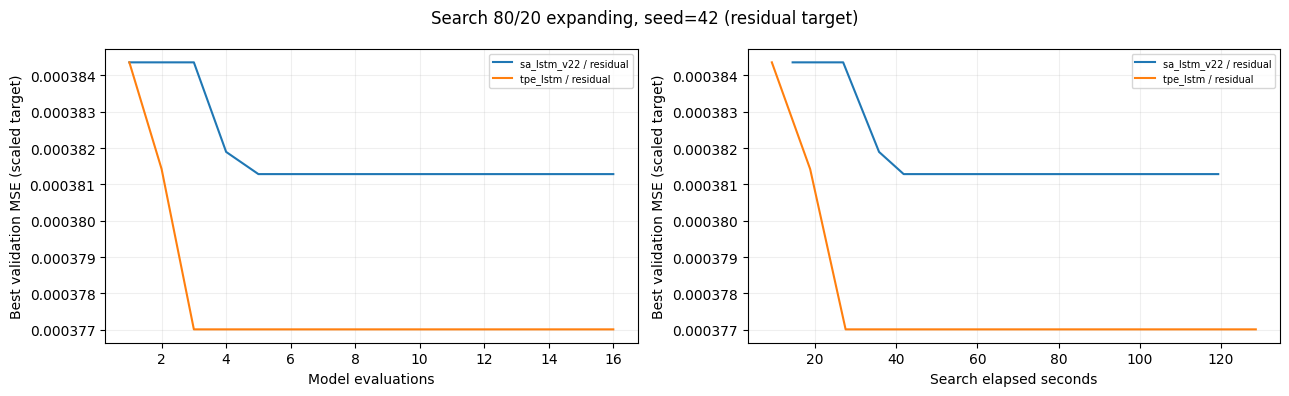

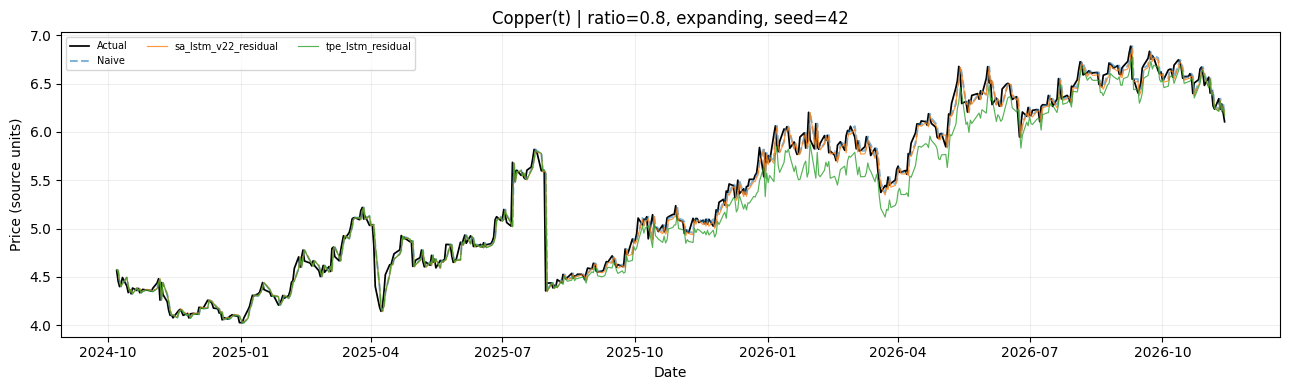

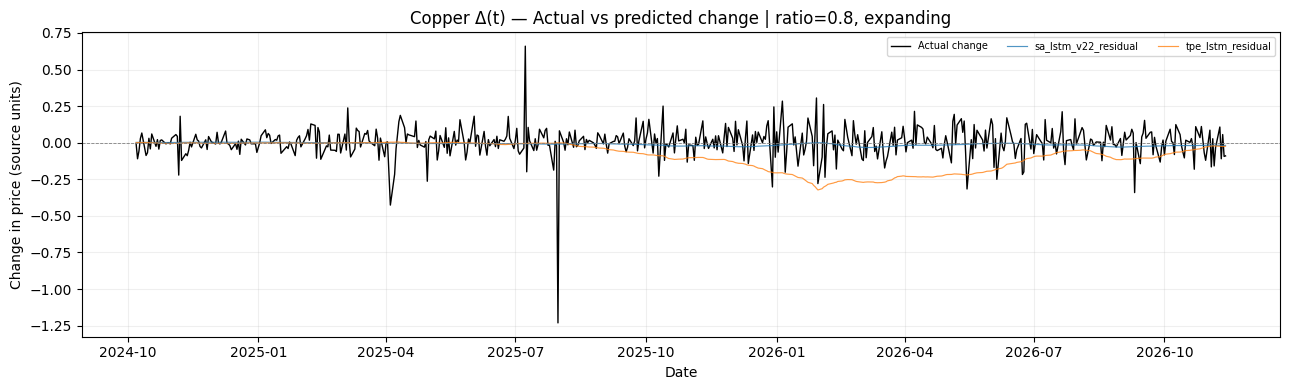

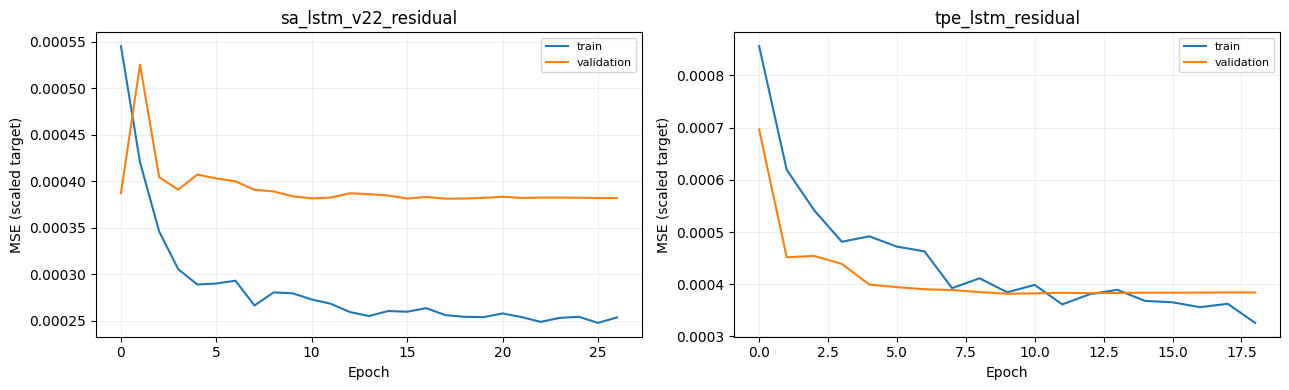

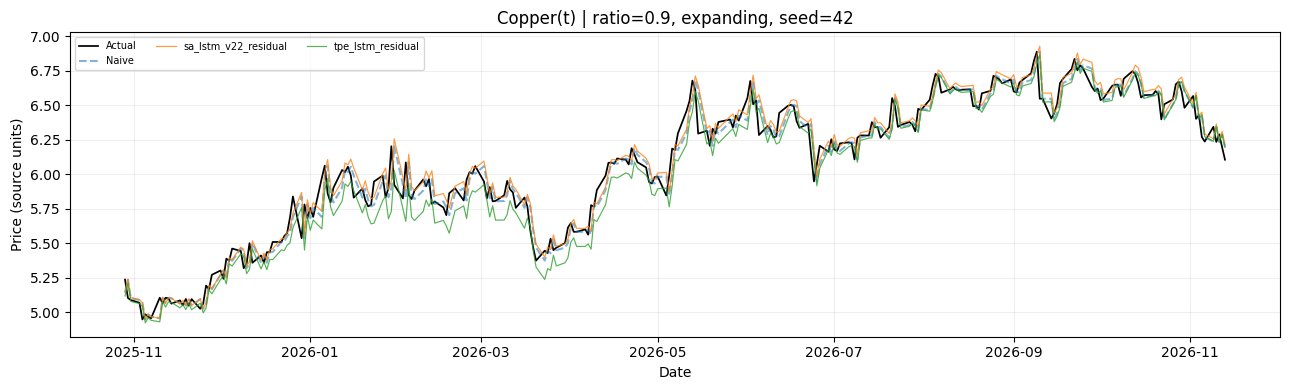

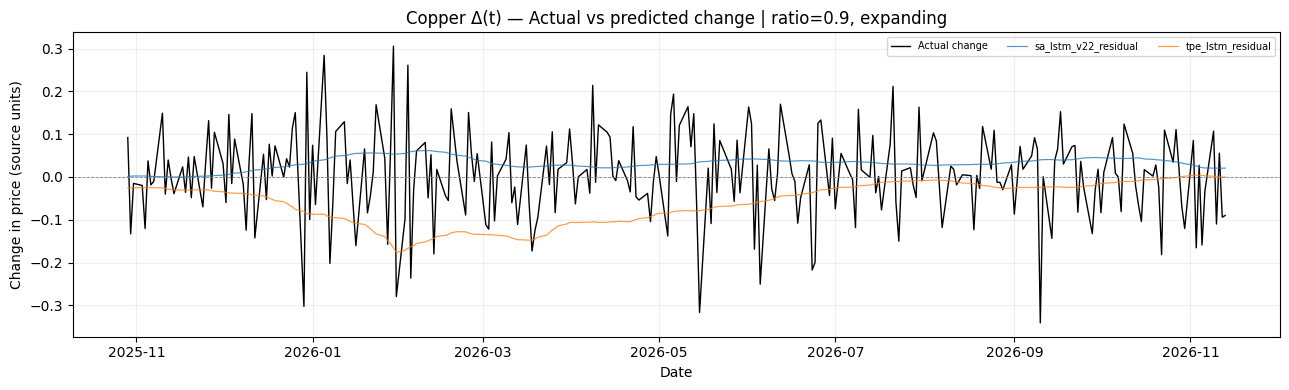

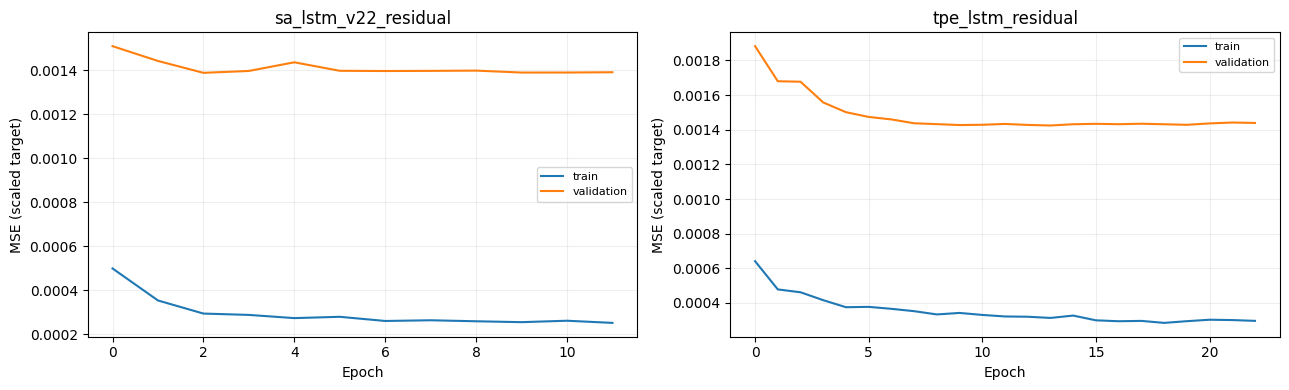

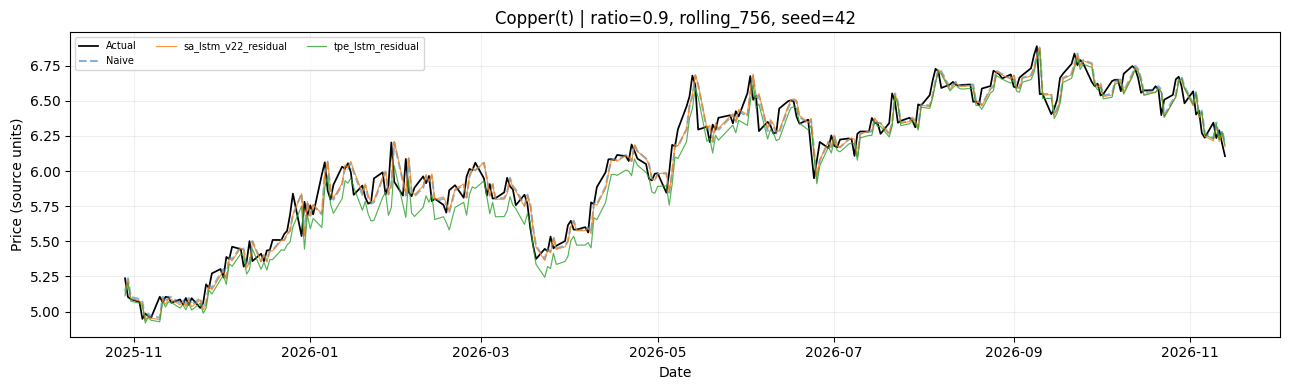

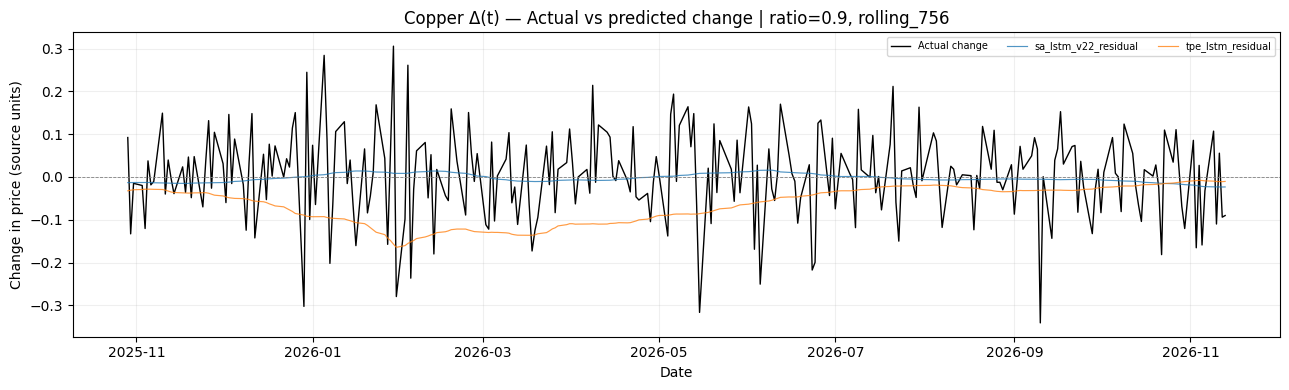

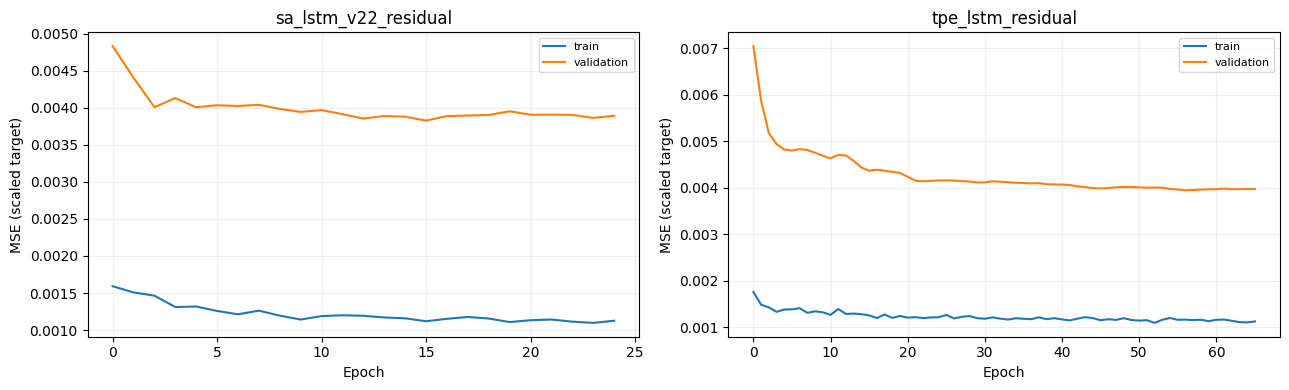

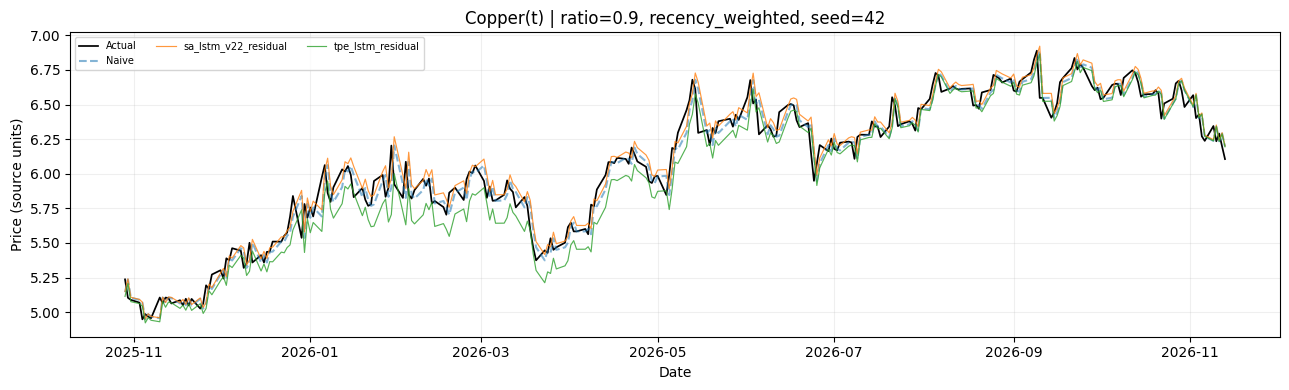

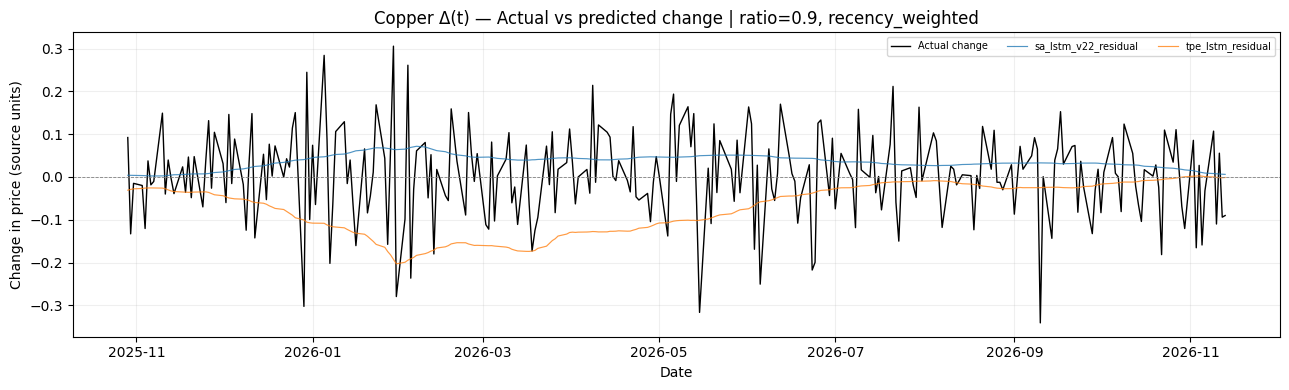

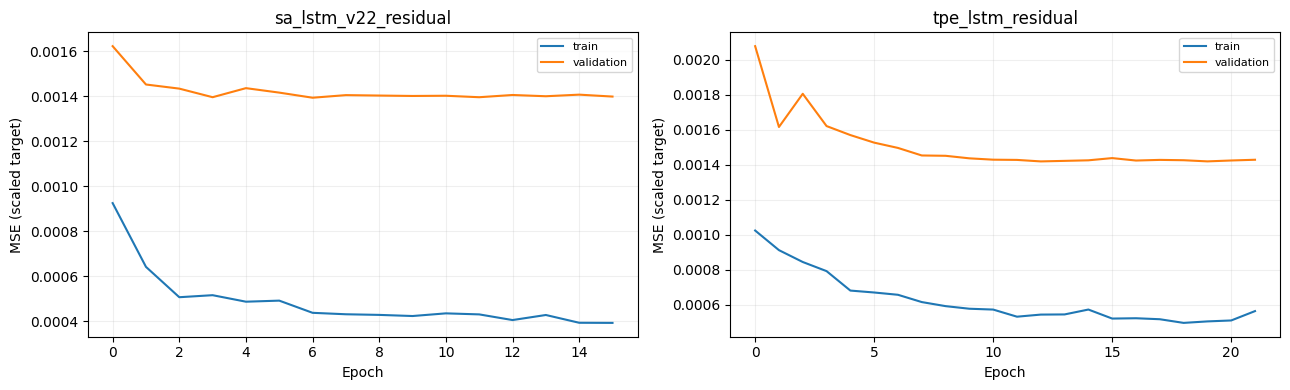

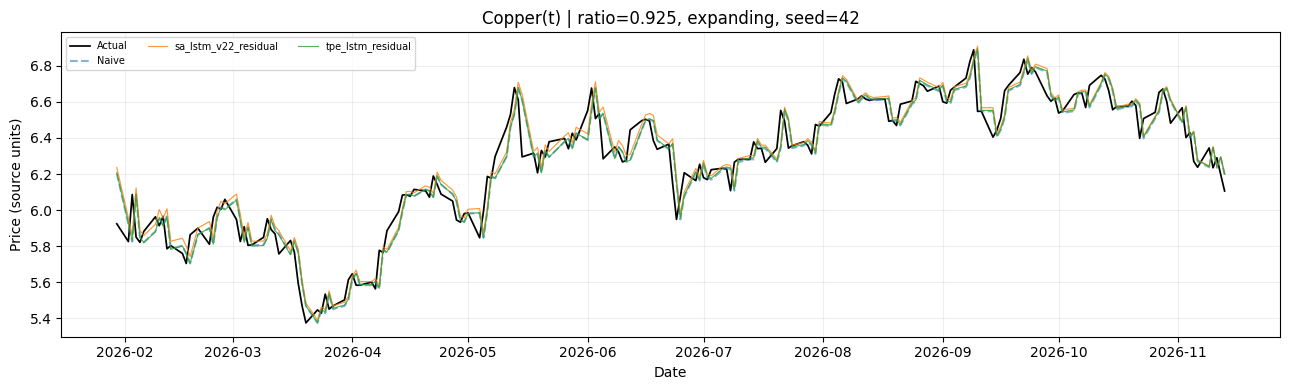

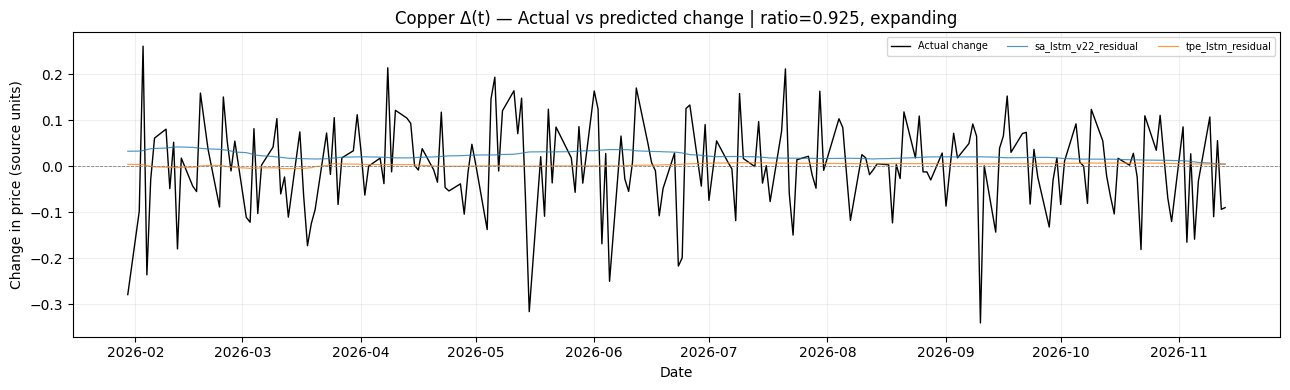

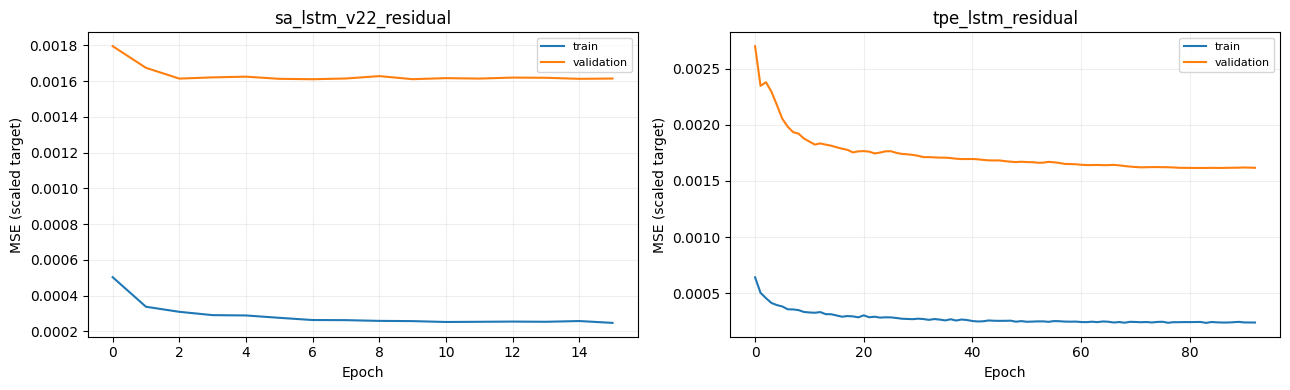

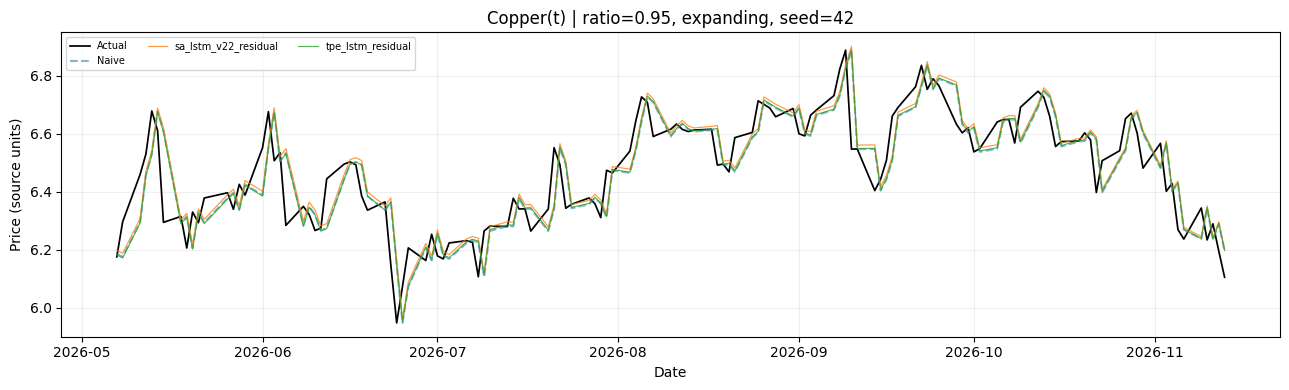

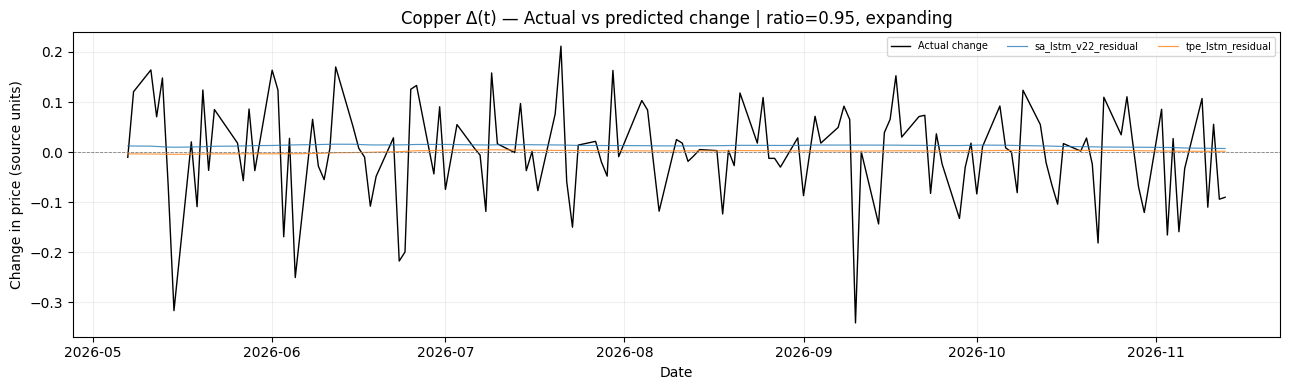

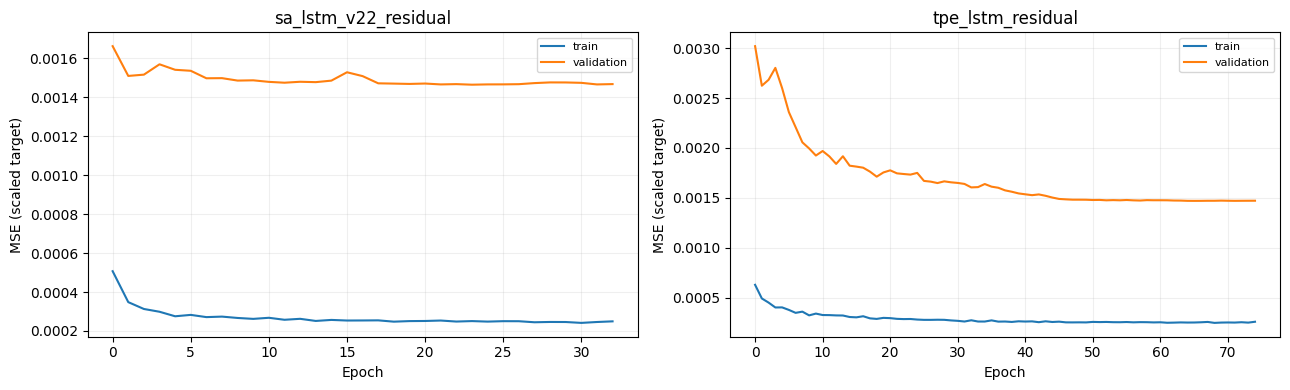

In [16]:
for seed in SEEDS:
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    for (mode,method),g in search_trials[search_trials.seed==seed].groupby(['forecast_mode','method']):
        g=g.sort_values('trial');label=f'{method} / {mode}'
        axs[0].plot(g.trial,g.best_val_mse_scaled,label=label)
        axs[1].plot(g.elapsed_seconds,g.best_val_mse_scaled,label=label)
    for ax in axs:
        ax.set_ylabel('Best validation MSE (scaled target)');ax.legend(fontsize=7);ax.grid(alpha=.2)
    axs[0].set_xlabel('Model evaluations');axs[1].set_xlabel('Search elapsed seconds')
    fig.suptitle(f'Search 80/20 expanding, seed={seed} (residual target)')
    fig.tight_layout();fig.savefig(OUT/f'search_convergence_{seed}.png',dpi=150)
    plt.show();plt.close(fig)

for ratio,scheme in JOBS:
    selected=predictions_df[(predictions_df.ratio==ratio)&(predictions_df.scheme==scheme)&
                            (predictions_df.seed==SEEDS[0])]
    ref=selected[selected.model_key==METHOD_LABELS[0]].sort_values('Date')
    fig,ax=plt.subplots(figsize=(13,4))
    ax.plot(ref.Date,ref.actual,color='black',label='Actual',linewidth=1.25)
    ax.plot(ref.Date,ref.naive,label='Naive',linestyle='--',alpha=.55)
    for model_key,g in selected.groupby('model_key'):
        g=g.sort_values('Date');ax.plot(g.Date,g.pred,label=model_key,alpha=.8,linewidth=.85)
    ax.set(title=f'Copper(t) | ratio={ratio}, {scheme}, seed={SEEDS[0]}',
           ylabel='Price (source units)',xlabel='Date')
    ax.legend(fontsize=7,ncol=3);ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(OUT/f'prediction_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(fig)

    fig,ax=plt.subplots(figsize=(13,4))
    ax.plot(ref.Date,ref.actual_delta,label='Actual change',color='black',linewidth=1.0)
    for model_key,g in selected.groupby('model_key'):
        g=g.sort_values('Date');ax.plot(g.Date,g.pred_delta,label=model_key,alpha=.78,linewidth=.85)
    ax.axhline(0,linestyle='--',color='gray',linewidth=.6)
    ax.set(title=f'Copper Δ(t) — Actual vs predicted change | ratio={ratio}, {scheme}',
           ylabel='Change in price (source units)',xlabel='Date')
    ax.legend(fontsize=7,ncol=3);ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(OUT/f'delta_prediction_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(fig)

    fig,axs=plt.subplots(1,2,figsize=(13,4))
    for ax,model_key in zip(axs.ravel(),METHOD_LABELS):
        recipe=next(r for r in final_models if r['model_key']==model_key and
                    r['ratio']==ratio and r['scheme']==scheme and r['seed']==SEEDS[0])
        hist=pd.read_csv(Path(recipe['model_path']).with_name(f'{model_key}_loss.csv'))
        ax.plot(hist.loss,label='train');ax.plot(hist.val_loss,label='validation')
        ax.set(title=model_key,xlabel='Epoch',ylabel='MSE (scaled target)')
        ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(OUT/f'loss_{ratio}_{scheme}.png',dpi=150)
    plt.show();plt.close(fig)


## 8. Tệp đầu ra residual

- `manifest.json`, snapshot, quality và split summary: dữ liệu và giao thức.
- `search_comparison.csv`, `all_search_trials.csv`, `locked_best_hyperparameters.json`: hai nhánh tuning residual SA/TPE.
- `final_training.csv`, `final_model_recipes.json`, `.keras`, loss CSV, scalers: final residual models.
- `metrics_by_run.csv`, `summary_mean_std.csv`, `naive_baseline.csv`: sai số dự báo giá và baseline.
- `paired_comparison_SA_vs_TPE_by_mode.csv`: TPE − SA, chỉ residual, cùng ratio/scheme/seed; không còn bảng đối chiếu giữa các target.
- `test_predictions.csv` và hình hội tụ, mức giá, delta, loss: chỉ hai nhánh residual cộng đường Naive tham chiếu.

Dự báo mức giá có thể sát thực tế vì đã cộng giá Copper phiên trước. Cần xem cải thiện so Naive, delta_corr và độ dao động delta dự báo để đánh giá giá trị gia tăng. Kết quả chỉ được tạo sau khi chạy; một seed chưa đủ kết luận độ ổn định.


In [17]:
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.rglob('*')):
        if file.is_file():z.write(file,arcname=str(file.relative_to(OUT)))
print('Results:',OUT)
print('ZIP:',zip_path)
display(FileLink(str(zip_path)))


Results: /kaggle/working/copper_sa_vs_tpe_k5_residual_only/20261120T125750886401Z
ZIP: /kaggle/working/copper_sa_vs_tpe_k5_residual_only/20261120T125750886401Z_results.zip


/kaggle/working/copper_sa_vs_tpe_k5_residual_only/20261120T125750886401Z_results.zip